### Imports

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

### Van der Pol System

The Van der Pol system we will first look at is the following:
$$\dot{x} = y$$
$$\dot{y} = \mu(1-x^2)y-x$$

#### Define Deterministic Trajectory

Functions: `vanderpol(t, z, mu)` and `solve_vanderpol(x0, y0, T, N, mu)`

In [24]:
def vanderpol(t, z, mu):

    """
    Function Inputs:
    t               = current time
    z               = current coordinate pair [x,y]
    mu              = Van der Pol parameter

    Function Outputs:
    [dxdt, dydt]    = Van der Pol oscillator first derivative values
    
    """

    x, y = z
    dxdt = y
    dydt = mu * (1 - x**2) * y - x
    
    return [dxdt, dydt]

def solve_vanderpol(x0, y0, T, N, mu):
    
    """
    Function Inputs:
    x0      = initial condition of x
    y0      = initial condition of y
    T       = total time amount (e.g. 1 year)
    N       = number of time steps
    mu      = Van der Pol parameter

    Function Outputs:
    t       = array of time points
    x       = simulated x values
    y       = simulated y values
    
    """

    t_span = (0, T)
    t = np.linspace(0, T, N + 1)

    trajectory = solve_ivp(vanderpol, t_span, [x0, y0], args=(mu,), t_eval=t)

    x = trajectory.y[0]
    y = trajectory.y[1]

    return t, x, y

### Introducing Noise

The next step in evaluating the Van der Pol oscillator is to introduce additive noise to the system. To model such a system, we will use the Euler-Murayama method to discretize the system and plot randomly-induced tipping points. The Euler scheme for the Van der Pol system is as follows:
$$x_{n+1} = x_{n}+ y \Delta t + \sigma_1 \sqrt{\Delta t} N(0,1)$$
$$y_{n+1} = y_n + (\mu(1-x^2)y-x) \Delta t + \sigma_2 \sqrt{\Delta t} N(0,1)$$
where $\sigma_1, \sigma_2 > 0$ denote noise strength.

#### Define Euler-Maruyama Method

Function: `euler_murayama(x0, y0, T, N, mu, sigma1, sigma2)`

In [25]:
def euler_maruyama(x0, y0, T, N, mu, sigma1, sigma2):

    """
    Function Inputs:
    x0      = initial condition of x
    y0      = initial condition of y
    T       = total time amount (e.g. 1 year)
    N       = number of time steps
    mu      = Van der Pol parameter
    sigma1  = noise strength parameter for x
    sigma2  = noise strength parameter for y

    Function Outputs:
    t       = array of time points
    x       = simulated x values
    y       = simulated y values
    
    """

    time_increment = T / N
    t = np.linspace(0, T, N + 1)
    x = np.zeros(N + 1) 
    y = np.zeros(N + 1)

    # Set initial conditions
    x[0] = x0
    y[0] = y0

    # Draw random variables for additive noise
    x_noise = np.random.normal(0, 1, N)
    y_noise = np.random.normal(0, 1, N)

    for n in range(N):

        # Numerically simulate change in Weiner process
        dW1 = np.sqrt(time_increment) * x_noise[n]
        dW2 = np.sqrt(time_increment) * y_noise[n]

        # Call Van der Pol function
        f1, f2 = vanderpol(t[n], [x[n], y[n]], mu)

        # Euler-Murayama update
        x[n+1] = x[n] + f1 * time_increment + sigma1 * dW1
        y[n+1] = y[n] + f2 * time_increment + sigma2 * dW2

    return t, x, y

### Running the System

#### Define Parameter Values

In [110]:
mu      = 0.5    # Van der Pol parameter
sigma1  = 0.5    # Noise strength for x
sigma2  = 0.5    # Noise strength for y
x0      = 3.0    # Initial x value
y0      = 3.0    # Initial y value
T       = 40     # Total amount of time
N       = 2000   # Number of time steps

#### Run Euler-Murayama Method in Monte Carlo Simulation

In [111]:
# Run the simulation
time_grid_sim, simulated_x, simulated_y = euler_maruyama(x0, y0, T, N, mu, sigma1, sigma2)

#### Run Deterministic Trajectories

In [112]:
# Run the Van der Pol oscillator without noise
time_grid_det, deterministic_x, deterministic_y = solve_vanderpol(x0, y0, T, N, mu)

#### Plot Simulation vs Deterministic System

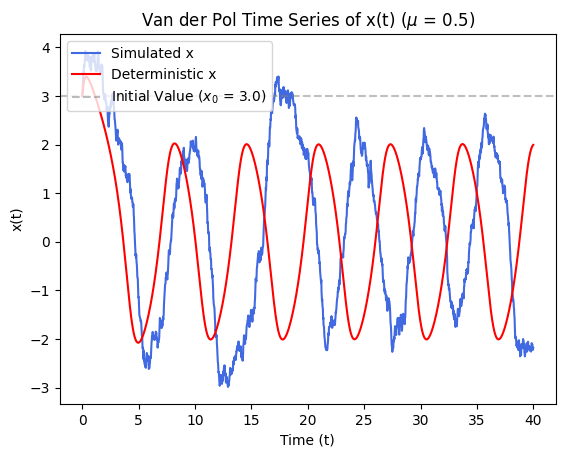

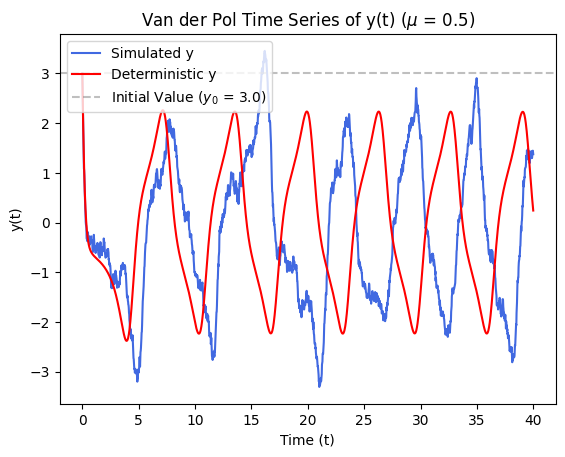

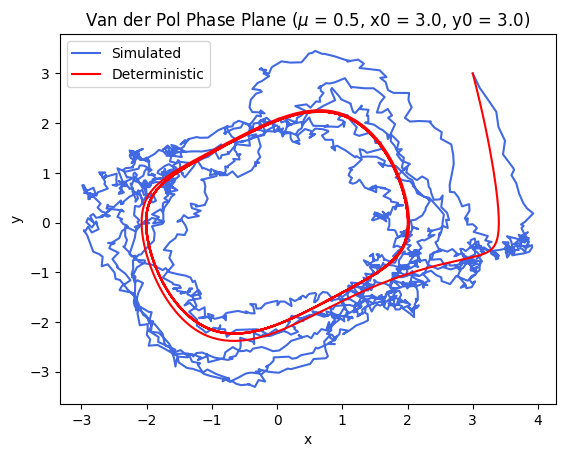

In [113]:
# Plot time-series of x
plt.figure(1)
plt.plot(time_grid_sim, simulated_x, label="Simulated x", color="royalblue", lw=1.5)
plt.plot(time_grid_det, deterministic_x, label="Deterministic x", color="red", lw=1.5)
plt.axhline(x0, color="gray", linestyle="--", alpha=0.5, label=f"Initial Value ($x_0$ = {x0})")

plt.title(fr"Van der Pol Time Series of x(t) ($\mu$ = {mu})", fontsize=12)
plt.xlabel("Time (t)")
plt.ylabel("x(t)")
plt.legend(loc="upper left")


# Plot time-series of y
plt.figure(2)
plt.plot(time_grid_sim, simulated_y, label="Simulated y", color="royalblue", lw=1.5)
plt.plot(time_grid_det, deterministic_y, label="Deterministic y", color="red", lw=1.5)
plt.axhline(y0, color="gray", linestyle="--", alpha=0.5, label=f"Initial Value ($y_0$ = {y0})")

plt.title(fr"Van der Pol Time Series of y(t) ($\mu$ = {mu})", fontsize=12)
plt.xlabel("Time (t)")
plt.ylabel("y(t)")
plt.legend(loc="upper left")


# Plot phase plane
plt.figure(3)
plt.plot(simulated_x, simulated_y, label="Simulated", color="royalblue", lw=1.5)
plt.plot(deterministic_x, deterministic_y, label="Deterministic", color="red", lw=1.5)

plt.title(fr"Van der Pol Phase Plane ($\mu$ = {mu}, x0 = {x0}, y0 = {y0})", fontsize=12)
plt.xlabel("x")
plt.ylabel("y")
plt.legend(loc="upper left")


# Show plots
plt.show()